# 08. Evaluación comparativa de portafolios

Los motores 05, 06 y 07 resuelven **la misma tarea de despliegue**
—un portafolio de $B$ sitios candidatos bajo reglas de red
idénticas— con métodos distintos: similitud de entornos (Motor 1),
predicción supervisada del bosque aleatorio (Motor 2) y afinidad
determinista de saltos al núcleo dorado (Motor 3). Este cuaderno
compara sus **portafolios ya publicados**: no reejecuta ningún
motor, lee los artefactos verificados byte a byte y reconstruye las
métricas del contrato del cuaderno 04 para comprobar que lo
publicado es reproducible.

La comparación es **descriptiva**: no se declara un ganador global.
Los ejes del radar están en escalas fijas $[0,1]$ con semántica
propia —su área **no** es un puntaje— y codifican objetivos en
tensión (cobertura, equidad, similitud).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from IPython.display import display, Markdown, JSON

BASE = Path.cwd().resolve()
PROJECT = next(p / "4_proyecto" for p in [BASE, *BASE.parents] if (p / "4_proyecto/V3/data").is_dir())
V3_DIR = PROJECT / "V3"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from V3.src.c8_analysis import CONFIG, RADAR_AXES, load_inputs, analyze
from V3.src.c8_publication import stage_results
from V3.src import fe04_deployment as dep

GREEN, GRAY, BLUE, RED, GOLD = "#004731", "#546E7A", "#0D47A1", "#B03A2E", "#B8860B"
MOTOR_COLOR = {"m1": GREEN, "m2": BLUE, "m3": GOLD}
MOTOR_LABEL = {"m1": "Motor 1 · similitud",
               "m2": "Motor 2 · bosque aleatorio",
               "m3": "Motor 3 · afinidad de saltos"}
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11})
data = load_inputs(V3_DIR)
result = analyze(data, verbose=True)
report = result["report"]
display(pd.DataFrame([{
    "contract_id": report["contract_id"],
    "analysis_version": report["schema_version"],
    "shared_validation_analysis_id":
        report["shared_validation_analysis_id"],
    "motor1": report["upstream"]["motor1_analysis_id"],
    "motor2": report["upstream"]["motor2_analysis_id"],
    "motor3": report["upstream"]["motor3_analysis_id"],
    "never_reruns_motors": report["scope"]["never_reruns_motors"],
}]))

[c8] ctx: 0.3s


[c8] catalog: 0.3s


[c8] metrics+consistency: 0.6s


[c8] overlap: 0.6s


[c8] asignacion: 0.7s


[c8] backtest: 0.7s


,contract_id,analysis_version,shared_validation_analysis_id,motor1,motor2,motor3,never_reruns_motors
0,6e586b3d9a0bd8b844d9cf5bc714f0e583fc2a6936f8cd...,v3-comparacion-2,ed7bf47bafab10ca2b3144e9d38f1d06e5024ee9ba6af3...,879ae45d46b56fc5504c9817be154eee0e78ab0e13ddfd...,4027385dff30ab79689dfdeb3c468260176080e83b1abd...,3aa53121add31f2ea2381259d0b44fa7f603fa758b4a73...,True


## 1. Chequeo de consistencia

Antes de comparar, el cuaderno reconstruye el contexto del contrato
—sitios, celdas, adyacencias e incidencia— y **recalcula las
métricas** de cada portafolio publicado: deben coincidir con lo que
cada motor reportó (tolerancia $10^{-9}$) y pasar el verificador
independiente `is_feasible` —ya sin techos por AGEB, retirados en
las versiones vigentes de los motores 1 y 2—. Los tres motores
deben referenciar el **mismo** analysis_id del cuaderno 04.
Cualquier divergencia aborta la publicación.

In [2]:
cons = report["consistency"]
display(pd.Series({
    "portafolios_verificados": cons["n_portfolios_checked"],
    "todos_factibles": cons["all_feasible"],
    "todas_metricas_reproducidas": cons["all_metrics_reproduced"],
    "rtol": cons["rtol"],
}, name="valor").to_frame())
display(pd.DataFrame(cons["checked"]))

,valor
portafolios_verificados,10
todos_factibles,True
todas_metricas_reproducidas,True
rtol,0.0


,tag,n_selected,is_feasible,metrics_equal
0,m1/greedy/B15,15,True,True
1,m2/random_forest/B15,15,True,True
2,m3/greedy/B15,15,True,True
3,m1/greedy/B30,30,True,True
4,m2/random_forest/B30,30,True,True
5,m3/greedy/B30,30,True,True
6,m1/greedy/B50,50,True,True
7,m2/random_forest/B50,50,True,True
8,m3/greedy/B50,50,True,True
9,m3/ga_best/B30,30,True,True


## 2. Contexto metodológico de esta versión

Tres notas condicionan la lectura de toda la comparación:

- **Los motores 1 y 2 ya no usan techos por AGEB.** El techo por
  análogos reproducía la densidad histórica de planeación —no la
  demanda— y su backtest perdía contra una densidad constante; sus
  portafolios **cambiaron** respecto a la versión previa (el cambio
  de $B=30$ se muestra abajo, leído de los campos publicados por
  cada motor).
- **El Motor 3 optimiza directamente la cercanía a Golden.** Su
  afinidad es $1/(1+\text{saltos a Golden})$: los ejes de
  proximidad a la red o a Golden que lo favorecen están **por
  construcción** —no son evidencia independiente—.
- **El prescriptor del Motor 3 es el greedy, no el GA.** La tabla
  abajo —leída del reporte del 07— muestra $f$, brecha y tiempos de
  pared medidos de ambos métodos por peso y presupuesto.

In [3]:
ctx8 = report["method_context"]
display(Markdown("**Remoción del techo — cambio publicado a B=30**"))
rows = []
for mot, lab in [("m1_techo_removido", "Motor 1"),
                 ("m2_techo_removido", "Motor 2")]:
    tr = ctx8[mot]
    if tr:
        rows.append({"motor": lab,
                     "esquema_previo": tr["previous_schema"],
                     "new_pop_previo_B30":
                         tr["previous_B30"]["new_pop"],
                     "new_pop_actual_B30":
                         tr["current_B30"]["new_pop"],
                     "delta_new_pop": tr["delta_B30_new_pop"],
                     "delta_n_agebs": tr["delta_B30_n_agebs"]})
display(pd.DataFrame(rows))
display(Markdown("**Motor 3 — greedy vs GA** (leído del reporte "
                 "publicado del 07)"))
gg = pd.DataFrame(ctx8["m3_ga_vs_greedy"])
display(gg[["weight", "budget", "greedy_f", "ga_best_f",
            "ga_mean_f", "ga_minus_greedy", "jaccard_ga_greedy",
            "greedy_wall_s", "ga_total_wall_s", "verdict"]])
display(Markdown(
    f"**Advertencia del Motor 3.** {ctx8['m3_affinity_scope_warning']}"))

**Remoción del techo — cambio publicado a B=30**

,motor,esquema_previo,new_pop_previo_B30,new_pop_actual_B30,delta_new_pop,delta_n_agebs
0,Motor 1,v3-motor1-2,153809.570982,202337.349801,48527.778819,0
1,Motor 2,v3-motor2-2,275943.271073,282101.840575,6158.569502,-1


**Motor 3 — greedy vs GA** (leído del reporte publicado del 07)

,weight,budget,greedy_f,ga_best_f,ga_mean_f,ga_minus_greedy,jaccard_ga_greedy,greedy_wall_s,ga_total_wall_s,verdict
0,0.00,30,0.137024,0.136098,0.135635,-0.000926,0.875000,0.020524,171.517598,greedy
1,0.25,30,0.200107,0.198534,0.193284,-0.001573,0.111111,0.011971,137.079007,empate (|brecha| <= std entre semillas)
2,0.50,30,0.289702,0.283511,0.276510,-0.006191,0.132075,0.016096,256.998508,greedy
3,0.50,15,0.298166,0.288860,0.285666,-0.009306,0.111111,0.009143,121.274078,greedy
4,0.50,50,0.280902,0.265145,0.260085,-0.015757,0.190476,0.030119,264.844171,greedy
5,0.75,30,0.380034,0.370643,0.352997,-0.009391,0.090909,0.017582,173.387520,empate (|brecha| <= std entre semillas)
6,1.00,30,0.470366,0.456551,0.447595,-0.013815,0.153846,0.017979,177.534930,greedy


**Advertencia del Motor 3.** la afinidad es función directa de los saltos a Golden: las métricas de cercanía a Golden del portafolio (saltos máximos y mediana) quedan optimizadas POR CONSTRUCCIÓN y NO constituyen evidencia independiente a favor del Motor 3

## 3. Cobertura y eficiencia

Tabla completa de métricas del contrato por motor y presupuesto, y
curva de población nueva cubierta contra la cota submodular
$P_{\text{norm}}$ —la misma referencia para los tres métodos—.

,0,1,2,3,4,5,6,7,8
motor,m1,m2,m3,m1,m2,m3,m1,m2,m3
variant,greedy,random_forest,greedy,greedy,random_forest,greedy,greedy,random_forest,greedy
tier,oficial,oficial,oficial,oficial,oficial,oficial,oficial,oficial,oficial
budget,15,15,15,30,30,30,50,50,50
n_selected,15,15,15,30,30,30,50,50,50
new_pop,113528.207285,136490.415242,166731.061854,202337.349801,282101.840575,310287.81353,300803.122124,428400.765425,481553.561453
new_pop_share,0.014248,0.01713,0.020925,0.025393,0.035404,0.038941,0.037751,0.053765,0.060435
redundancy,0.6358,0.538192,0.502053,0.625619,0.525186,0.521415,0.643574,0.601413,0.576122
n_agebs,10,12,14,21,25,28,33,41,46
max_hops_network,6,6,10,14,8,12,21,17,15


**Filas de sensibilidad** (no oficiales)

,9
motor,m3
variant,ga_best
tier,sensibilidad
budget,30
n_selected,30
new_pop,305089.725633
new_pop_share,0.038289
redundancy,0.571111
n_agebs,26
max_hops_network,11


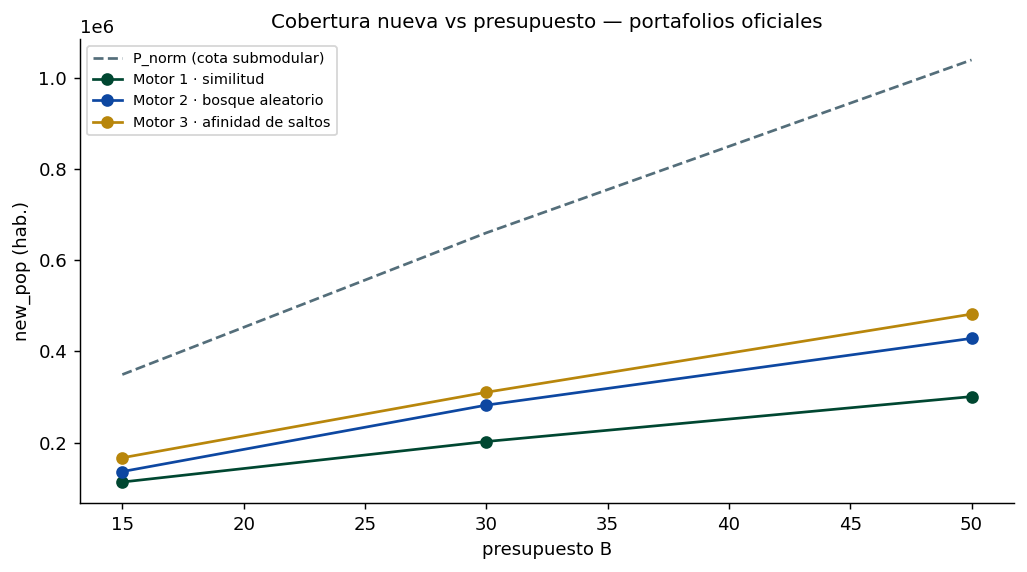

In [4]:
met = result["metricas"]
of = met.loc[met.tier.eq("oficial")]
display(pd.DataFrame(of).T)
display(Markdown("**Filas de sensibilidad** (no oficiales)"))
display(pd.DataFrame(met.loc[met.tier.eq("sensibilidad")]).T)
fig, ax = plt.subplots(figsize=(8, 4.5))
pnorm = of.drop_duplicates("budget").set_index("budget").p_norm
ax.plot(pnorm.index, pnorm.values, "--", color=GRAY,
        label="P_norm (cota submodular)")
for m, g in of.groupby("motor"):
    g = g.sort_values("budget")
    ax.plot(g.budget, g.new_pop, "-o", color=MOTOR_COLOR[m],
            label=MOTOR_LABEL[m])
ax.set(xlabel="presupuesto B", ylabel="new_pop (hab.)",
       title="Cobertura nueva vs presupuesto — portafolios oficiales")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Radar y mapa de calor

Seis ejes en escala fija $[0,1]$: **cobertura** ($new\_pop/P_{norm}$),
**eficiencia** ($1-$redundancia), **proximidad a la red**
($1-\bar d_{red}/\text{alcanzable}$), **equidad** (fracción de sitios
en AGEBs bajo la mediana de escolaridad de todos los sitios),
**similitud al núcleo** ($1-$fracción fuera del dominio global del
04) y **dispersión** ($n_{AGEB}/n_{sitios}$). El área del radar
**no es un puntaje**: los ejes codifican objetivos distintos y en
tensión, y es un dispositivo de presentación, no una evaluación.
**El eje de proximidad a la red del Motor 3 es favorable por
construcción** (su afinidad son los saltos a Golden).

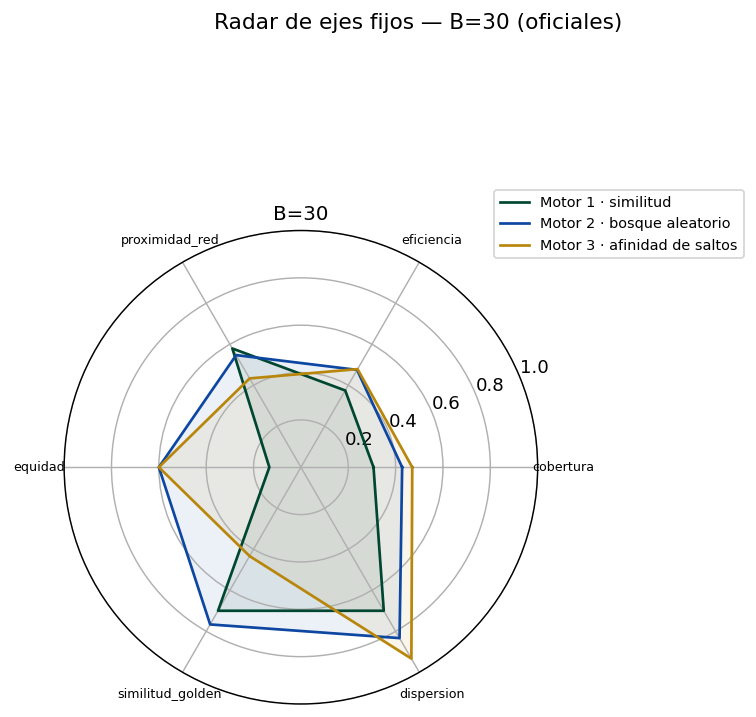

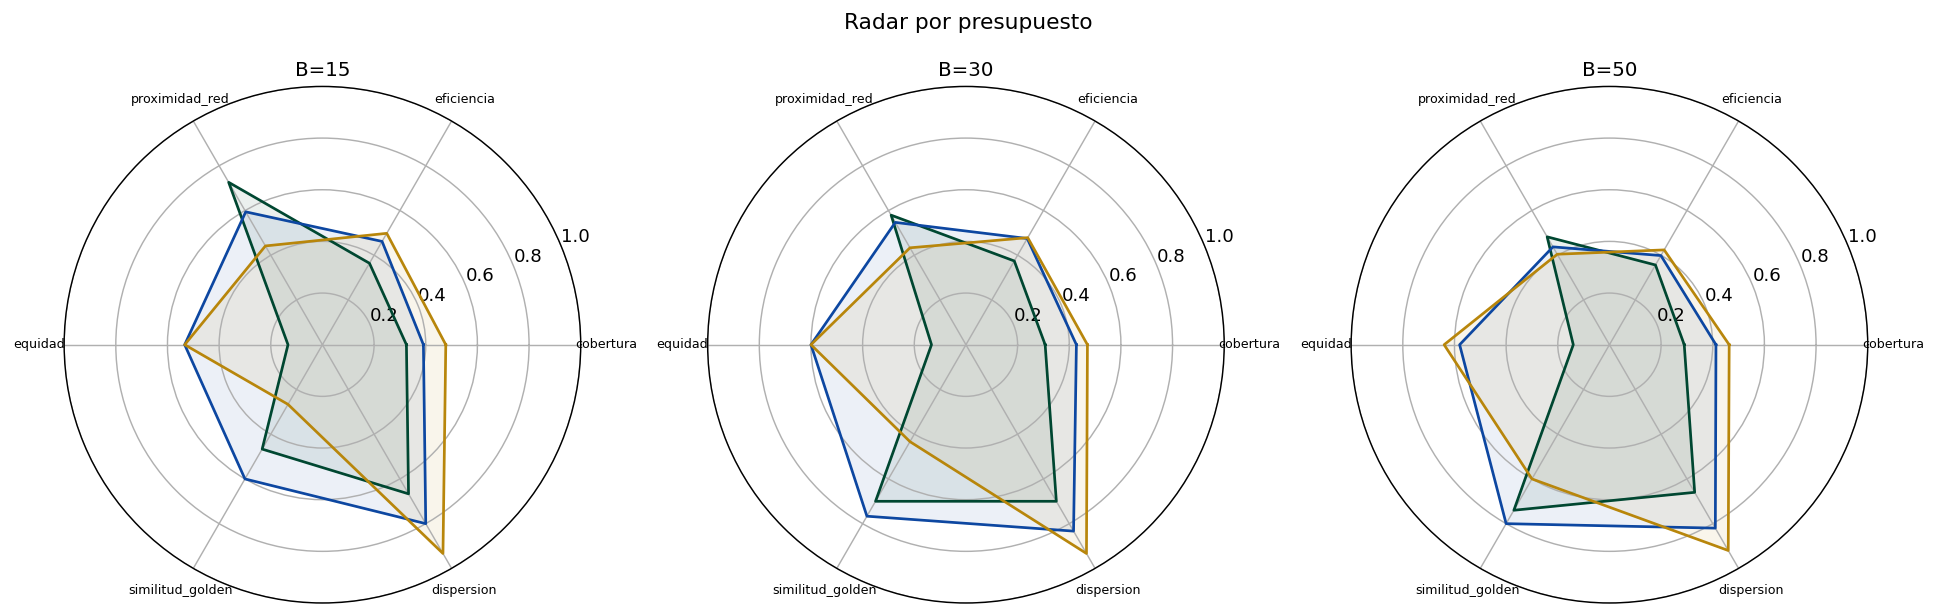

In [5]:
radar = result["radar"].loc[lambda r: r.tier.eq("oficial")]
angles = np.linspace(0, 2 * np.pi, len(RADAR_AXES), endpoint=False)
angles = np.r_[angles, angles[:1]]
def _radar(ax, budget):
    sub = radar.loc[radar.budget.eq(budget)]
    for m, g in sub.groupby("motor"):
        vals = g.set_index("axis").reindex(RADAR_AXES)["value"]
        v = np.r_[vals.to_numpy(float), vals.to_numpy(float)[:1]]
        ax.plot(angles, v, color=MOTOR_COLOR[m],
                label=MOTOR_LABEL[m])
        ax.fill(angles, v, color=MOTOR_COLOR[m], alpha=0.08)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels(RADAR_AXES,
                                                 fontsize=7)
    ax.set_ylim(0, 1); ax.set_title(f"B={budget}")
b_grid = sorted(radar.budget.unique())
b_main = CONFIG["primary_budget"]
fig, ax = plt.subplots(figsize=(6.5, 6.5),
                       subplot_kw={"polar": True})
_radar(ax, b_main); ax.legend(fontsize=8, loc="upper right",
                             bbox_to_anchor=(1.45, 1.1))
plt.suptitle(f"Radar de ejes fijos — B={b_main} (oficiales)")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, len(b_grid), figsize=(5 * len(b_grid), 5),
                         subplot_kw={"polar": True})
for ax, b in zip(np.atleast_1d(axes), b_grid):
    _radar(ax, b)
plt.suptitle("Radar por presupuesto")
plt.tight_layout(); plt.show()

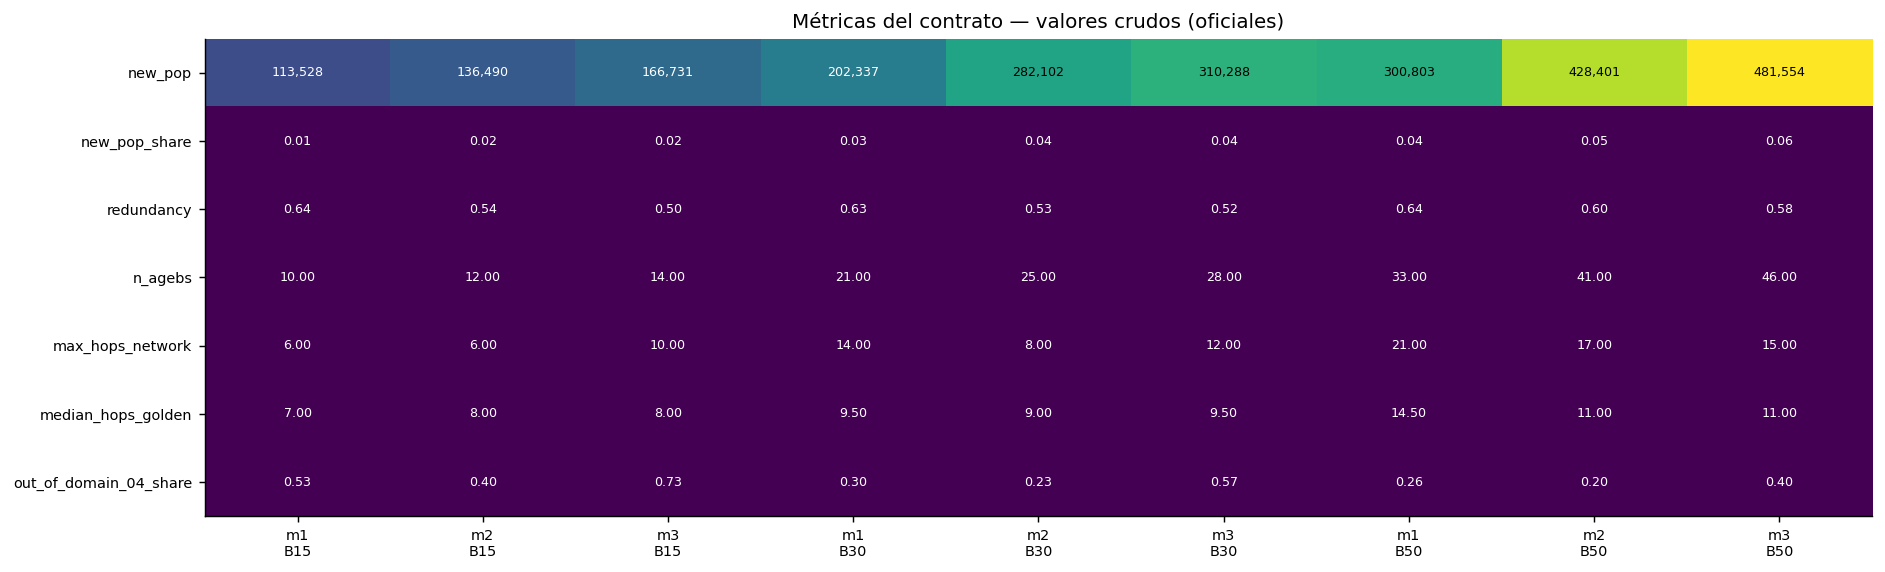

In [6]:
cols = ["new_pop", "new_pop_share", "redundancy", "n_agebs",
        "max_hops_network", "median_hops_golden",
        "out_of_domain_04_share"]
pivot = of.set_index(["motor", "budget"])[cols].T
fig, ax = plt.subplots(figsize=(2 + 1.4 * len(pivot.columns), 4.5))
im = ax.imshow(pivot.to_numpy(float), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([f"{m}\nB{b}" for m, b in pivot.columns],
                   fontsize=8)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8)
for i in range(len(cols)):
    for j in range(len(pivot.columns)):
        v = pivot.to_numpy(float)[i, j]
        ax.text(j, i, f"{v:,.2f}" if abs(v) < 100 else f"{v:,.0f}",
                ha="center", va="center", fontsize=7,
                color="white" if v < np.nanmax(
                    pivot.to_numpy(float)) / 2 else "black")
ax.set_title("Métricas del contrato — valores crudos (oficiales)")
plt.tight_layout(); plt.show()

## 5. Asignación territorial: ¿cuántas estaciones por AGEB?

La respuesta del proyecto a «¿una o tres estaciones por AGEB?» es
**condicional al presupuesto y al método**: la tabla muestra cuántas
AGEBs reciben 1, 2 o 3+ sitios por motor y presupuesto. Los techos
por análogos fueron retirados de los motores 1 y 2: el número de
estaciones por AGEB es ahora únicamente el resultado de la
cobertura con rendimientos decrecientes.

,motor,budget,n_agebs,agebs_1,agebs_2,agebs_3plus
0,m1,15,10,8,1,1
1,m2,15,12,10,1,1
2,m3,15,14,13,1,0
3,m1,30,21,15,5,1
4,m2,30,25,21,3,1
5,m3,30,28,26,2,0
6,m1,50,33,20,11,2
7,m2,50,41,33,7,1
8,m3,50,46,42,4,0


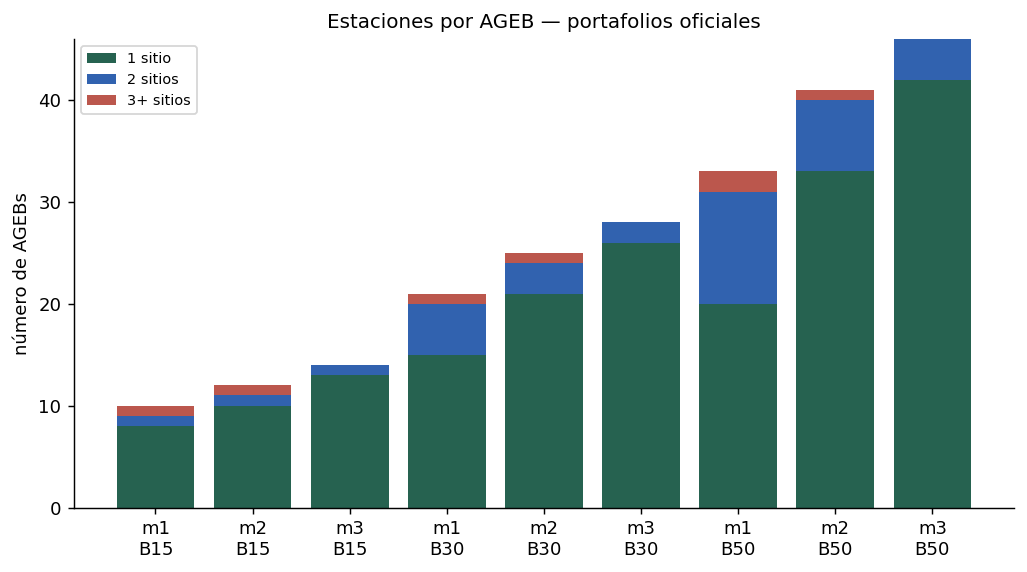

In [7]:
display(result["asignacion"])
asig = result["asignacion"]
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [f"{m}\nB{b}" for m, b in zip(asig.motor, asig.budget)]
bottom = np.zeros(len(asig))
for col, color, lab in [("agebs_1", GREEN, "1 sitio"),
                        ("agebs_2", BLUE, "2 sitios"),
                        ("agebs_3plus", RED, "3+ sitios")]:
    ax.bar(labels, asig[col], bottom=bottom, color=color,
           label=lab, alpha=0.85)
    bottom += asig[col].to_numpy(float)
ax.set(ylabel="número de AGEBs",
       title="Estaciones por AGEB — portafolios oficiales")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Traslape y consenso

Jaccard por parejas de motores sobre los **conjuntos de sitios** y
sobre los **conjuntos de AGEBs** cubiertos, y sitios de consenso —
elegidos por 2 o por los 3 motores—: evidencia de que los métodos
convergen o divergen territorialmente.

,budget,motor_a,motor_b,n_a_sites,n_b_sites,n_inter_sites,jaccard_sites,n_a_agebs,n_b_agebs,n_inter_agebs,jaccard_agebs
0,15,m1,m2,15,15,8,0.363636,10,12,5,0.294118
1,15,m1,m3,15,15,3,0.111111,10,14,2,0.090909
2,15,m2,m3,15,15,4,0.153846,12,14,4,0.181818
3,30,m1,m2,30,30,9,0.176471,21,25,6,0.150000
4,30,m1,m3,30,30,5,0.090909,21,28,4,0.088889
5,30,m2,m3,30,30,12,0.250000,25,28,11,0.261905
6,50,m1,m2,50,50,11,0.123596,33,41,9,0.138462
7,50,m1,m3,50,50,7,0.075269,33,46,6,0.082192
8,50,m2,m3,50,50,26,0.351351,41,46,26,0.426230


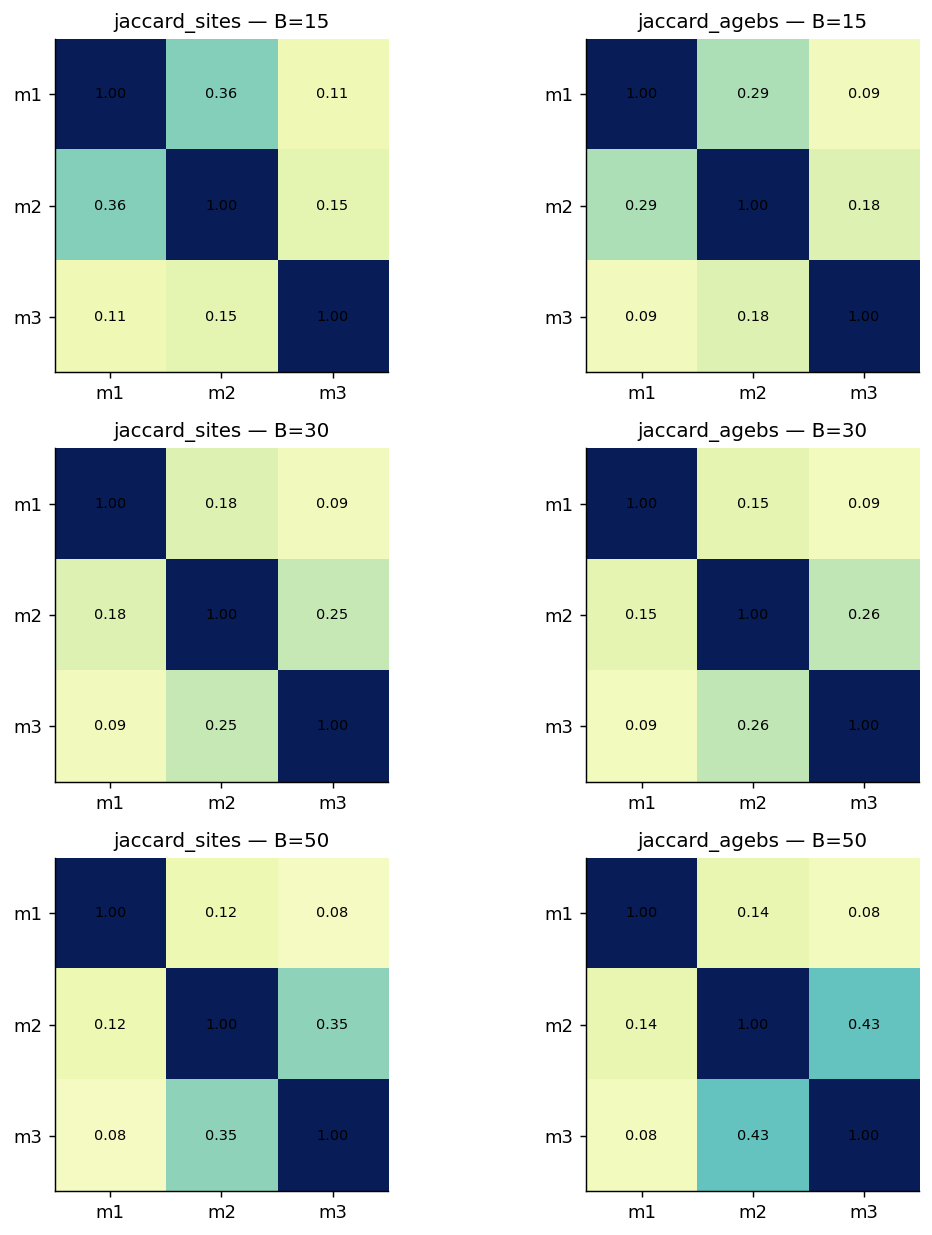

**Sitios de consenso por presupuesto**

,selected_by_2plus,selected_by_3
15,9,3
30,18,4
50,32,6


In [8]:
ov = result["overlap"]
display(ov)
b_grid = sorted(ov.budget.unique())
fig, axes = plt.subplots(len(b_grid), 2,
                         figsize=(9, 3.2 * len(b_grid)))
for r, b in enumerate(b_grid):
    for c, kind in enumerate(["jaccard_sites", "jaccard_agebs"]):
        ax = axes[r, c] if len(b_grid) > 1 else axes[c]
        M = np.eye(3)
        motors = ["m1", "m2", "m3"]
        sub = ov.loc[ov.budget.eq(b)]
        for _, row in sub.iterrows():
            i, j = motors.index(row.motor_a), motors.index(row.motor_b)
            M[i, j] = M[j, i] = row[kind]
        im = ax.imshow(M, vmin=0, vmax=1, cmap="YlGnBu")
        for i in range(3):
            for j in range(3):
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center",
                        va="center", fontsize=8)
        ax.set_xticks(range(3)); ax.set_yticks(range(3))
        ax.set_xticklabels(motors); ax.set_yticklabels(motors)
        ax.set_title(f"{kind} — B={b}")
plt.tight_layout(); plt.show()
display(Markdown("**Sitios de consenso por presupuesto**"))
display(pd.DataFrame(report["consensus_counts"]).T)

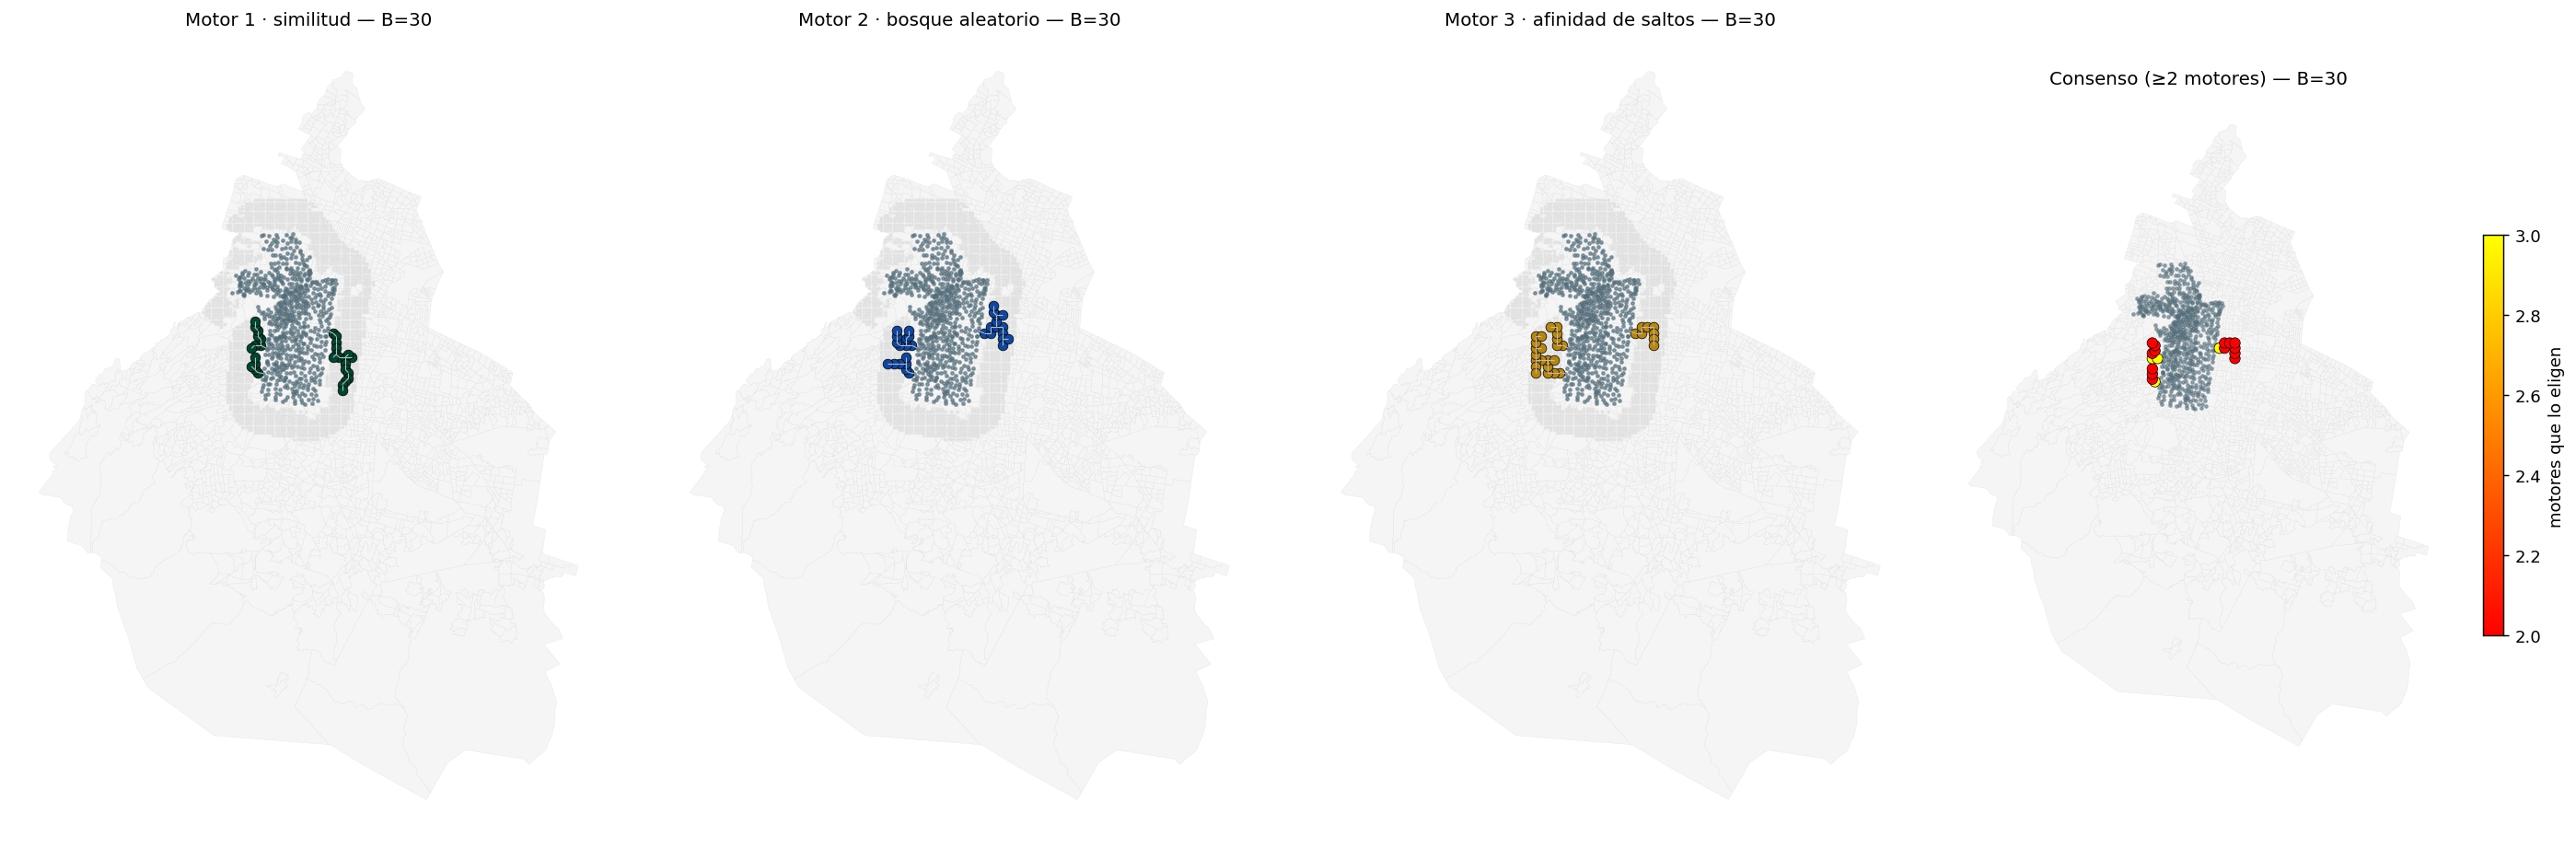

In [9]:
universe = result["universe04"]
universe = features_plot = result["features"].to_crs(
    CONFIG["metric_crs"])
sites = result["sites"]
stations = result["stations"]
b_main = CONFIG["primary_budget"]
catalog = {f"{e['motor']}|{e['variant']}|{e['budget']}": e["sel"]
           for e in result["catalog"]}
station_xy = {str(s): (g.x, g.y) for s, g in
              zip(stations.station_id, stations.geometry)}
site_xy = {s: (g.x, g.y) for s, g in zip(sites.site_id,
                                       sites.geometry)}
def _attach_xy(a):
    if str(a).startswith("est:"):
        return station_xy.get(str(a)[4:])
    return site_xy.get(a)
fig, axes = plt.subplots(1, 4, figsize=(22, 7))
for ax, m in zip(axes[:3], ["m1", "m2", "m3"]):
    universe.plot(ax=ax, color="#F5F5F5", edgecolor="#DDDDDD",
                  linewidth=0.15)
    sites.plot(ax=ax, color="#DDDDDD", markersize=1.5, alpha=0.5)
    sel = catalog[[k for k in catalog
                   if k.startswith(f"{m}|") and
                   k.endswith(f"|{b_main}")][0]]
    segs = []
    for _, row in sel.iterrows():
        dst = _attach_xy(row.attach)
        if dst is not None:
            segs.append([(row.geometry.x, row.geometry.y), dst])
    if segs:
        ax.add_collection(LineCollection(
            segs, colors="#BBBBBB", linewidths=0.6, zorder=2))
    stations.plot(ax=ax, color=GRAY, markersize=3, alpha=0.6)
    sel.plot(ax=ax, color=MOTOR_COLOR[m], markersize=35,
             edgecolor="black", linewidth=0.4)
    ax.set_axis_off()
    ax.set_title(f"{MOTOR_LABEL[m]} — B={b_main}")
ax = axes[3]
universe.plot(ax=ax, color="#F5F5F5", edgecolor="#DDDDDD",
              linewidth=0.15)
cons = result["consensus"]
cons_b = cons.loc[cons.budget.eq(b_main)] if len(cons) else cons
stations.plot(ax=ax, color=GRAY, markersize=3, alpha=0.5)
if len(cons_b):
    cons_b.plot(ax=ax, column="n_motors", cmap="autumn",
                markersize=40, edgecolor="black", linewidth=0.4,
                legend=True, vmin=2, vmax=3,
                legend_kwds={"label": "motores que lo eligen",
                             "shrink": 0.5})
ax.set_axis_off(); ax.set_title(f"Consenso (≥2 motores) — B={b_main}")
plt.tight_layout(); plt.show()

## 7. La tensión equidad–similitud

El hallazgo central de la comparación es una tensión de objetivos:
el Motor 1 selecciona sitios en AGEBs **semejantes** a la referencia
de alta actividad —perfiles afluentes—; la cobertura poblacional
empuja hacia la periferia densa y menos afluente. Las barras
comparan la media de escolaridad y de hogares con auto de las AGEBs
seleccionadas contra la media de **todos** los sitios candidatos:
valores por encima de la línea indican sesgo hacia entornos
afluentes; por debajo, sesgo hacia los menos afluentes.

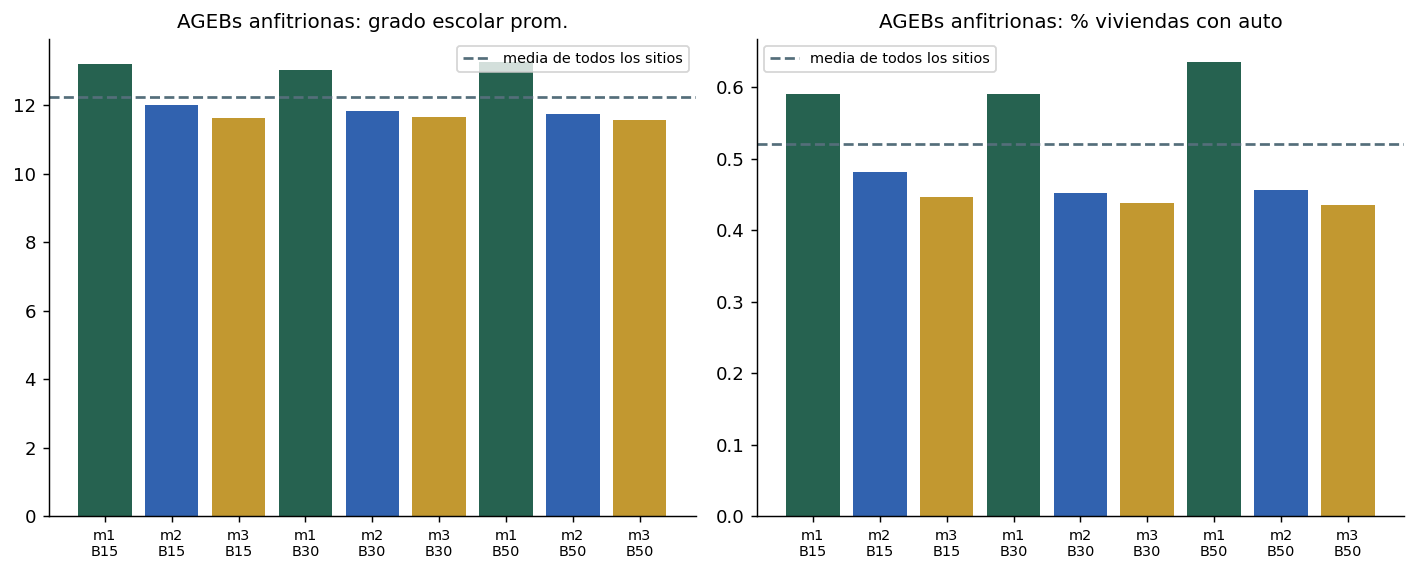

**Ejes equidad y similitud del radar**

axis           equidad  similitud_golden
motor budget                            
m1    15      0.133333          0.466667
      30      0.133333          0.700000
      50      0.140000          0.740000
m2    15      0.533333          0.600000
      30      0.600000          0.766667
      50      0.580000          0.800000
m3    15      0.533333          0.266667
      30      0.600000          0.433333
      50      0.640000          0.600000

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, lab in [
        (axes[0], "mean_grado_escolar_prom", "grado escolar prom."),
        (axes[1], "mean_pct_viviendas_auto", "% viviendas con auto")]:
    sel_c, all_c = f"{col}_selected", f"{col}_all_sites"
    x = np.arange(len(of))
    ax.bar(x, of[sel_c], color=[MOTOR_COLOR[m] for m in of.motor],
           alpha=0.85)
    ax.axhline(of[all_c].iloc[0], color=GRAY, linestyle="--",
               label="media de todos los sitios")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{m}\nB{b}" for m, b in
                        zip(of.motor, of.budget)], fontsize=8)
    ax.set_title(f"AGEBs anfitrionas: {lab}")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(Markdown("**Ejes equidad y similitud del radar**"))
display(radar.loc[radar.axis.isin(["equidad", "similitud_golden"])]
        .pivot_table(index=["motor", "budget"], columns="axis",
                     values="value"))

## 8. Contexto de backtest: qué puede afirmar cada motor

Estas cifras se **leen** de los reportes publicados —no se
recalculan— y contextualizan qué tipo de evidencia respalda cada
puntaje: los motores 1 y 2 tienen backtests de ranking sobre AGEBs
con servicio; el Motor 3 no —su puntaje es **afinidad estructural**,
no un modelo de actividad, así que no admite ese protocolo—.

In [11]:
display(result["backtest"])

,motor,subject,scheme,precision_at_10,recall_at_10,ndcg_at_10,decision_coverage,note
0,m1,m1_coseno_compuerta,fold_spatial_block,0.38,0.318556,0.673203,0.901017,None
1,m1,heur_metro,fold_spatial_block,0.30,0.326619,0.673633,1.000000,None
2,m1,control_aleatorio,fold_spatial_block,0.32,0.250978,0.540956,1.000000,None
3,m2,constante,fold_spatial_block,0.04,0.107692,0.383096,1.000000,None
4,m2,ridge,fold_spatial_block,0.38,0.242274,0.707271,1.000000,None
5,m2,random_forest,fold_spatial_block,0.38,0.186134,0.698559,1.000000,None
6,m2,ft_transformer,fold_spatial_block,0.36,0.190081,0.699055,1.000000,None
7,m3,afinidad_estructural,None,NaN,NaN,NaN,NaN,sin backtest de AGEB: el puntaje del Motor 3 e...


## 9. Conclusiones condicionales y límites

Las conclusiones de este cuaderno son **condicionales**: dependen del
presupuesto, del objetivo que se priorice y de los supuestos del
contrato —no existe un ganador global—.

- Si el criterio es **cobertura nueva**, los portafolios se ordenan
  por `new_pop` a cada presupuesto, con la cota `P_norm` como
  referencia común.
- Si el criterio es **semejanza al núcleo con servicio**, domina la
  similitud; si es **equidad territorial**, dominan los portafolios
  que bajan la escolaridad media de las AGEBs anfitrionas.
- El consenso entre motores identifica sitios robustos al método
  elegido; el traslape bajo identifica decisiones sensibles al
  método.

Límites compartidos: la interpolación areal de población y la
captura de 500 m son **supuestos**, no demanda observada; no hay red
vial, costos, factibilidad de terreno ni validación de campo; los
tres métodos son heurísticos sin garantía de optimalidad; la
comparación es descriptiva y el área del radar no es un puntaje.

In [12]:
display(pd.DataFrame({"pending_validation":
                      report["pending_validation"]}))
report_path = stage_results(V3_DIR, data, result)
display(Markdown("**Cierre.** Comparación verificada de los "
                 "portafolios publicados por los tres motores."))
display(JSON({"c8_report_path": report_path.relative_to(V3_DIR).as_posix()}))

,pending_validation
0,Comparison is descriptive: no aggregate winner...
1,Radar area is not a score; axes encode differe...
2,Motor 3 optimizes golden-hop affinity directly...
3,Motors 1 and 2 dropped analog ceilings; their ...
4,Areal interpolation and 500 m catchments are a...
5,"No street network, cost, or field validation"
6,Motor 3 has no AGEB backtest: its score is str...


**Cierre.** Comparación verificada de los portafolios publicados por los tres motores.

<IPython.core.display.JSON object>